# Churn Target, Extended Features and Train/Test Split
**Course:** Data Mining & Knowledge Discovery (505043) - TDTU
**Phase:** Final - Target & Pipelines (Data Engineer role)
**Dataset:** Online Retail II (Kaggle)

**What this notebook produces**
1. A binary **Churn** target built without target leakage
2. Extended behavioral features (basket size, item diversity, tenure, purchase rhythm, cancellations)
3. A stratified train/test split
4. A demonstration of **SMOTE** on the training split only
5. `churn_train.csv`, `churn_test.csv`, `churn_dataset.csv` for the modeling notebook

> **Scope note.** This notebook implements the data-engineering part of the final phase so that the modeling notebook has something to train on. If Member 1 has built an equivalent dataset, compare the two definitions (section 2) before merging.

## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
RAW_PATH = "online_retail_II.csv"            # fallback: ../online_retail_II.zip
if not Path(RAW_PATH).exists():
    RAW_PATH = "../online_retail_II.zip"
OUT = Path("dataset"); OUT.mkdir(exist_ok=True)

## 1. Load and clean (same rules as the midterm)
Cancelled invoices are **kept in a separate table** so that the cancellation rate can be used as a feature. They are excluded from sales, RFM and basket calculations.

In [2]:
raw = pd.read_csv(RAW_PATH, encoding="latin1")
raw = raw.rename(columns={"Customer ID": "CustomerID"})
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])
raw = raw.dropna(subset=["CustomerID"])
raw["CustomerID"] = raw["CustomerID"].astype(int)
raw["IsCancel"] = raw["Invoice"].astype(str).str.startswith("C")

cancels = raw[raw["IsCancel"]]
sales = raw[~raw["IsCancel"]]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].drop_duplicates().copy()
sales["Total"] = sales["Quantity"] * sales["Price"]

DATA_END = sales["InvoiceDate"].max()
print(f"Sales rows: {len(sales):,} | cancelled-invoice rows: {len(cancels):,} | data ends {DATA_END:%d %b %Y}")

Sales rows: 779,425 | cancelled-invoice rows: 18,744 | data ends 09 Dec 2011


## 2. Defining churn without target leakage
**The naive definition and its problem.** A common definition is *"churned = Recency > 90 days"*. If Recency is then used as an input feature, the model only has to rediscover that rule, and it scores almost perfectly without learning anything useful. The cell below demonstrates this.

In [3]:
rfm_raw = pd.read_csv("dataset/rfm_raw.csv") if Path("dataset/rfm_raw.csv").exists() else None
if rfm_raw is not None:
    naive = (rfm_raw["Recency"] > 90).astype(int)
    Xn = rfm_raw[["Recency", "Frequency", "Monetary"]]
    Xtr, Xte, ytr, yte = train_test_split(Xn, naive, test_size=0.2, stratify=naive, random_state=RANDOM_STATE)
    lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    print(f"Naive label (Recency > 90) with Recency as a feature: test ROC-AUC = {roc_auc_score(yte, lr.predict_proba(Xte)[:, 1]):.3f}")
    print("A near-perfect score here is a warning sign, not a success: the label is a function of the feature.")
else:
    print("dataset/rfm_raw.csv not found - skipping the demonstration.")

Naive label (Recency > 90) with Recency as a feature: test ROC-AUC = 1.000
A near-perfect score here is a warning sign, not a success: the label is a function of the feature.


**The definition used here: a forward-looking snapshot.**
- Pick a **cut-off date** 90 days before the end of the data.
- Build every feature **only from transactions before the cut-off**.
- **Churn = 1** if the customer bought before the cut-off but made **no purchase in the following 90 days**.

This keeps the 90-day inactivity idea from the project plan, but the label describes the *future* and the features describe the *past*, so no feature can contain the answer. Recency measured at the cut-off is a legitimate feature.

In [4]:
CHURN_WINDOW_DAYS = 90
CUTOFF = (DATA_END - pd.Timedelta(days=CHURN_WINDOW_DAYS)).normalize()
print(f"Cut-off date: {CUTOFF:%d %b %Y} | observation window: {CUTOFF:%d %b %Y} to {DATA_END:%d %b %Y}")

past = sales[sales["InvoiceDate"] < CUTOFF]
future = sales[sales["InvoiceDate"] >= CUTOFF]
past_cancel = cancels[cancels["InvoiceDate"] < CUTOFF]

customers = past["CustomerID"].unique()
returned = set(future["CustomerID"].unique())
churn = pd.Series([0 if c in returned else 1 for c in customers], index=pd.Index(customers, name="CustomerID"), name="Churn")
print(f"Customers with a purchase before the cut-off: {len(churn):,} | churned: {churn.sum():,} ({churn.mean():.1%})")

Cut-off date: 10 Sep 2011 | observation window: 10 Sep 2011 to 09 Dec 2011
Customers with a purchase before the cut-off: 5,281 | churned: 2,989 (56.6%)


## 3. Feature engineering (history before the cut-off only)

In [5]:
g = past.groupby("CustomerID")
inv = past.groupby(["CustomerID", "Invoice"]).agg(
    BasketValue=("Total", "sum"), BasketItems=("Quantity", "sum"), InvoiceDate=("InvoiceDate", "min")).reset_index()
gi = inv.groupby("CustomerID")

feat = pd.DataFrame({
    "Recency":        (CUTOFF - g["InvoiceDate"].max()).dt.days,
    "Frequency":      gi["Invoice"].nunique(),
    "Monetary":       g["Total"].sum(),
    "AvgBasketValue": gi["BasketValue"].mean(),
    "AvgBasketItems": gi["BasketItems"].mean(),
    "UniqueProducts": g["StockCode"].nunique(),
    "Tenure":         (CUTOFF - g["InvoiceDate"].min()).dt.days,
})
feat["ItemDiversity"] = feat["UniqueProducts"] / g["Quantity"].sum()          # distinct products per unit bought
span = (g["InvoiceDate"].max() - g["InvoiceDate"].min()).dt.days
feat["AvgDaysBetweenOrders"] = np.where(feat["Frequency"] > 1, span / (feat["Frequency"] - 1).clip(lower=1), feat["Tenure"])

recent = past[past["InvoiceDate"] >= CUTOFF - pd.Timedelta(days=90)].groupby("CustomerID")
feat["Orders_Last90d"] = recent["Invoice"].nunique().reindex(feat.index).fillna(0)
feat["Spend_Last90d"] = recent["Total"].sum().reindex(feat.index).fillna(0)

n_cancel = past_cancel.groupby("CustomerID")["Invoice"].nunique().reindex(feat.index).fillna(0)
feat["CancelRate"] = n_cancel / (feat["Frequency"] + n_cancel)

country = past.groupby("CustomerID")["Country"].agg(lambda s: s.mode().iloc[0])
feat["IsUK"] = (country.reindex(feat.index) == "United Kingdom").astype(int)

data = feat.join(churn).reset_index()
assert data["Churn"].notna().all() and data["CustomerID"].is_unique
assert not data.isna().any().any(), "Unexpected missing values"
print(data.shape)
data.head()

(5281, 15)


,CustomerID,Recency,Frequency,Monetary,AvgBasketValue,AvgBasketItems,UniqueProducts,Tenure,ItemDiversity,AvgDaysBetweenOrders,Orders_Last90d,Spend_Last90d,CancelRate,IsUK,Churn
0,12346,234,12,77556.46,6463.038333,6190.416667,27,634,0.000363,36.363636,0.0,0.00,0.294118,1,1
1,12347,38,6,3402.39,567.065000,349.833333,107,313,0.050977,54.800000,1.0,584.91,0.000000,0,0
2,12348,157,4,1709.40,427.350000,624.250000,25,347,0.010012,63.000000,0.0,0.00,0.000000,0,0
3,12349,316,3,2671.14,890.380000,331.000000,90,498,0.090634,90.500000,0.0,0.00,0.250000,0,0
4,12350,219,1,334.40,334.400000,197.000000,17,219,0.086294,219.000000,0.0,0.00,0.000000,0,1


In [6]:
FEATURES = [c for c in data.columns if c not in ("CustomerID", "Churn")]
display(data[FEATURES].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Recency,5281.0,206.81,175.03,0.0,49.00,163.00,326.00,647.00
Frequency,5281.0,5.75,11.46,1.0,1.00,3.00,6.00,309.00
Monetary,5281.0,2637.86,12225.54,2.9,318.24,783.58,2078.54,456780.49
AvgBasketValue,5281.0,369.29,538.21,2.9,174.67,276.86,409.72,14844.77
AvgBasketItems,5281.0,241.69,1400.04,1.0,87.00,148.00,251.00,87167.00
UniqueProducts,5281.0,74.36,104.97,1.0,18.00,41.00,92.00,2182.00
Tenure,5281.0,431.32,180.52,0.0,311.00,473.00,586.00,647.00
ItemDiversity,5281.0,0.13,0.14,0.0,0.06,0.09,0.15,1.00
AvgDaysBetweenOrders,5281.0,160.64,162.11,0.0,44.43,91.33,231.00,647.00
Orders_Last90d,5281.0,0.75,1.81,0.0,0.00,0.00,1.00,46.00


### Feature glossary
| Feature | Meaning |
|---|---|
| Recency | Days between the last purchase and the cut-off |
| Frequency | Number of orders before the cut-off |
| Monetary | Total spend before the cut-off |
| AvgBasketValue / AvgBasketItems | Average order value and units per order |
| UniqueProducts / ItemDiversity | Number of distinct products, and distinct products per unit bought |
| Tenure | Days since the first purchase |
| AvgDaysBetweenOrders | Typical gap between orders (tenure if only one order) |
| Orders_Last90d / Spend_Last90d | Activity in the 90 days before the cut-off |
| CancelRate | Share of the customer's invoices that were cancellations |
| IsUK | 1 if the customer's main country is the United Kingdom |

Standardized RFM scores are produced inside the modeling pipeline (`log1p` then `StandardScaler`, fitted on training data only).

### Feature relationships with churn

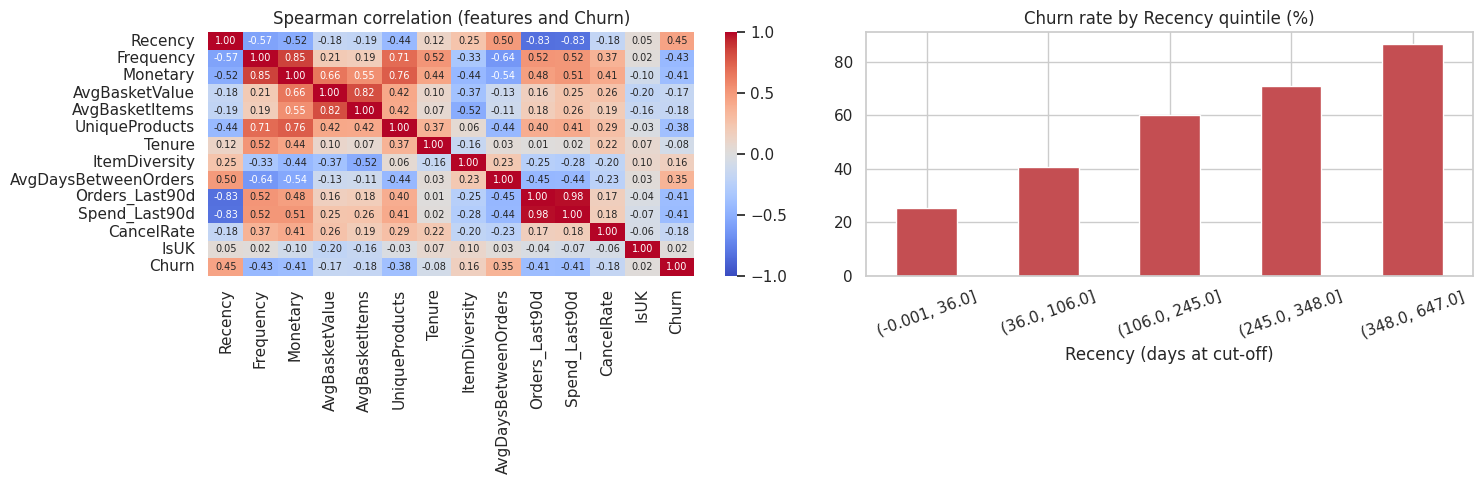

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(data[FEATURES + ["Churn"]].corr(method="spearman"), cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("Spearman correlation (features and Churn)")
rate = data.groupby(pd.qcut(data["Recency"], 5, duplicates="drop"))["Churn"].mean() * 100
rate.plot(kind="bar", color="#C44E52", ax=axes[1]); axes[1].set_title("Churn rate by Recency quintile (%)")
axes[1].set_xlabel("Recency (days at cut-off)"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 4. Train/test split (stratified)

In [8]:
train_df, test_df = train_test_split(data, test_size=0.2, stratify=data["Churn"], random_state=RANDOM_STATE)
print(f"Train: {len(train_df):,} ({train_df.Churn.mean():.1%} churn) | Test: {len(test_df):,} ({test_df.Churn.mean():.1%} churn)")

data.to_csv(OUT / "churn_dataset.csv", index=False)
train_df.to_csv(OUT / "churn_train.csv", index=False)
test_df.to_csv(OUT / "churn_test.csv", index=False)

Train: 4,224 (56.6% churn) | Test: 1,057 (56.6% churn)


## 5. Class imbalance and SMOTE
Here the churn rate is mildly imbalanced. SMOTE is applied to the **training split only**; the test set must keep its real class distribution. In the modeling notebook, SMOTE is part of an `imblearn` pipeline, so inside cross-validation it is fitted on the training folds only and never sees the validation fold.

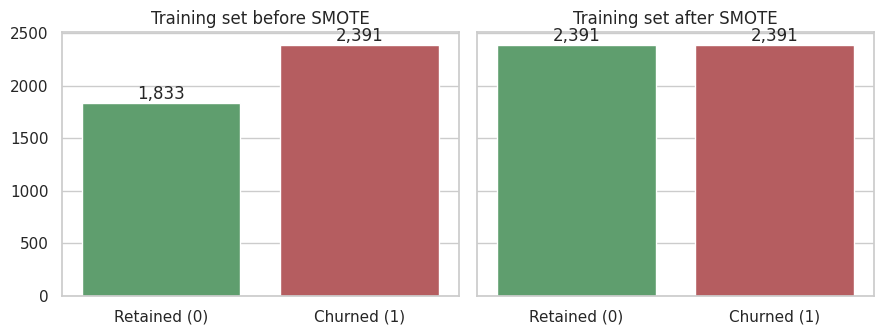

Test set is untouched: {1: 598, 0: 459}


In [9]:
Xtr = StandardScaler().fit_transform(np.log1p(train_df[FEATURES]))
ytr = train_df["Churn"].values
Xsm, ysm = SMOTE(random_state=RANDOM_STATE).fit_resample(Xtr, ytr)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, y, title in zip(axes, (ytr, ysm), ("Training set before SMOTE", "Training set after SMOTE")):
    vals = pd.Series(y).value_counts().sort_index()
    sns.barplot(x=["Retained (0)", "Churned (1)"], y=vals.values, palette=["#55A868", "#C44E52"], ax=ax)
    for i, v in enumerate(vals.values): ax.text(i, v, f"{v:,}", ha="center", va="bottom")
    ax.set_title(title)
plt.tight_layout(); plt.show()
print("Test set is untouched:", test_df["Churn"].value_counts().to_dict())

## 6. Summary
- Churn is defined as *no purchase in the 90 days after the cut-off*; features come only from before it.
- The dataset has one row per customer with 13 behavioral features.
- The split is stratified; SMOTE is demonstrated on the training split and integrated into the model pipeline in the next notebook.